In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
# COCO Class names
# Index of the class in the list is its ID. For example, to get ID of
# the teddy bear class, use: class_names.index('teddy bear')
class_names = ['BG', 'person', 'bicycle', 'car', 'motorcycle', 'airplane',
               'bus', 'train', 'truck', 'boat', 'traffic light',
               'fire hydrant', 'stop sign', 'parking meter', 'bench', 'bird',
               'cat', 'dog', 'horse', 'sheep', 'cow', 'elephant', 'bear',
               'zebra', 'giraffe', 'backpack', 'umbrella', 'handbag', 'tie',
               'suitcase', 'frisbee', 'skis', 'snowboard', 'sports ball',
               'kite', 'baseball bat', 'baseball glove', 'skateboard',
               'surfboard', 'tennis racket', 'bottle', 'wine glass', 'cup',
               'fork', 'knife', 'spoon', 'bowl', 'banana', 'apple',
               'sandwich', 'orange', 'broccoli', 'carrot', 'hot dog', 'pizza',
               'donut', 'cake', 'chair', 'couch', 'potted plant', 'bed',
               'dining table', 'toilet', 'tv', 'laptop', 'mouse', 'remote',
               'keyboard', 'cell phone', 'microwave', 'oven', 'toaster',
               'sink', 'refrigerator', 'book', 'clock', 'vase', 'scissors',
               'teddy bear', 'hair drier', 'toothbrush']

# Loading Mask RCNN
nn = cv2.dnn.readNetFromTensorflow("./frozen_inference_graph_coco.pb", "./mask_rcnn_inception_v2_coco_2018_01_28.pbtxt")


img = cv2.imread('./human_detection.jpg')
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
image=img.copy()
height, width, _ = img.shape

# Detect objects
blob = cv2.dnn.blobFromImage(img, swapRB=True)
nn.setInput(blob)
boxes, masks = nn.forward(["detection_out_final", "detection_masks"])

detection_count = boxes.shape[2]
print(detection_count)
for i in range(detection_count):
    box = boxes[0, 0, i]
    class_id = box[1]
    score = box[2]
    if score < 0.5:
        continue
    # Get box Coordinates
    x = int(box[3] * width)
    y = int(box[4] * height)
    x2 = int(box[5] * width)
    y2 = int(box[6] * height)
    roi = img[y: y2, x: x2]
    roi_height, roi_width, _ = roi.shape

    # Get the mask
    mask = masks[i, int(class_id)]
    mask = cv2.resize(mask, (roi_width, roi_height))
    _, mask = cv2.threshold(mask, 0.5, 255, cv2.THRESH_BINARY)

    cv2.rectangle(image, (x, y), (x2, y2), (255, 0, 0), 3)

    # Get mask coordinates
    contours, _ = cv2.findContours(np.array(mask, np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    # for cnt in contours:
    #     cv2.fillPoly(roi, [cnt], (np.random.randint(0,255), np.random.randint(0,255), np.random.randint(0,255)))


image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
plt.imshow(image)
plt.show()


Inference time 0.9366538524627686 sec


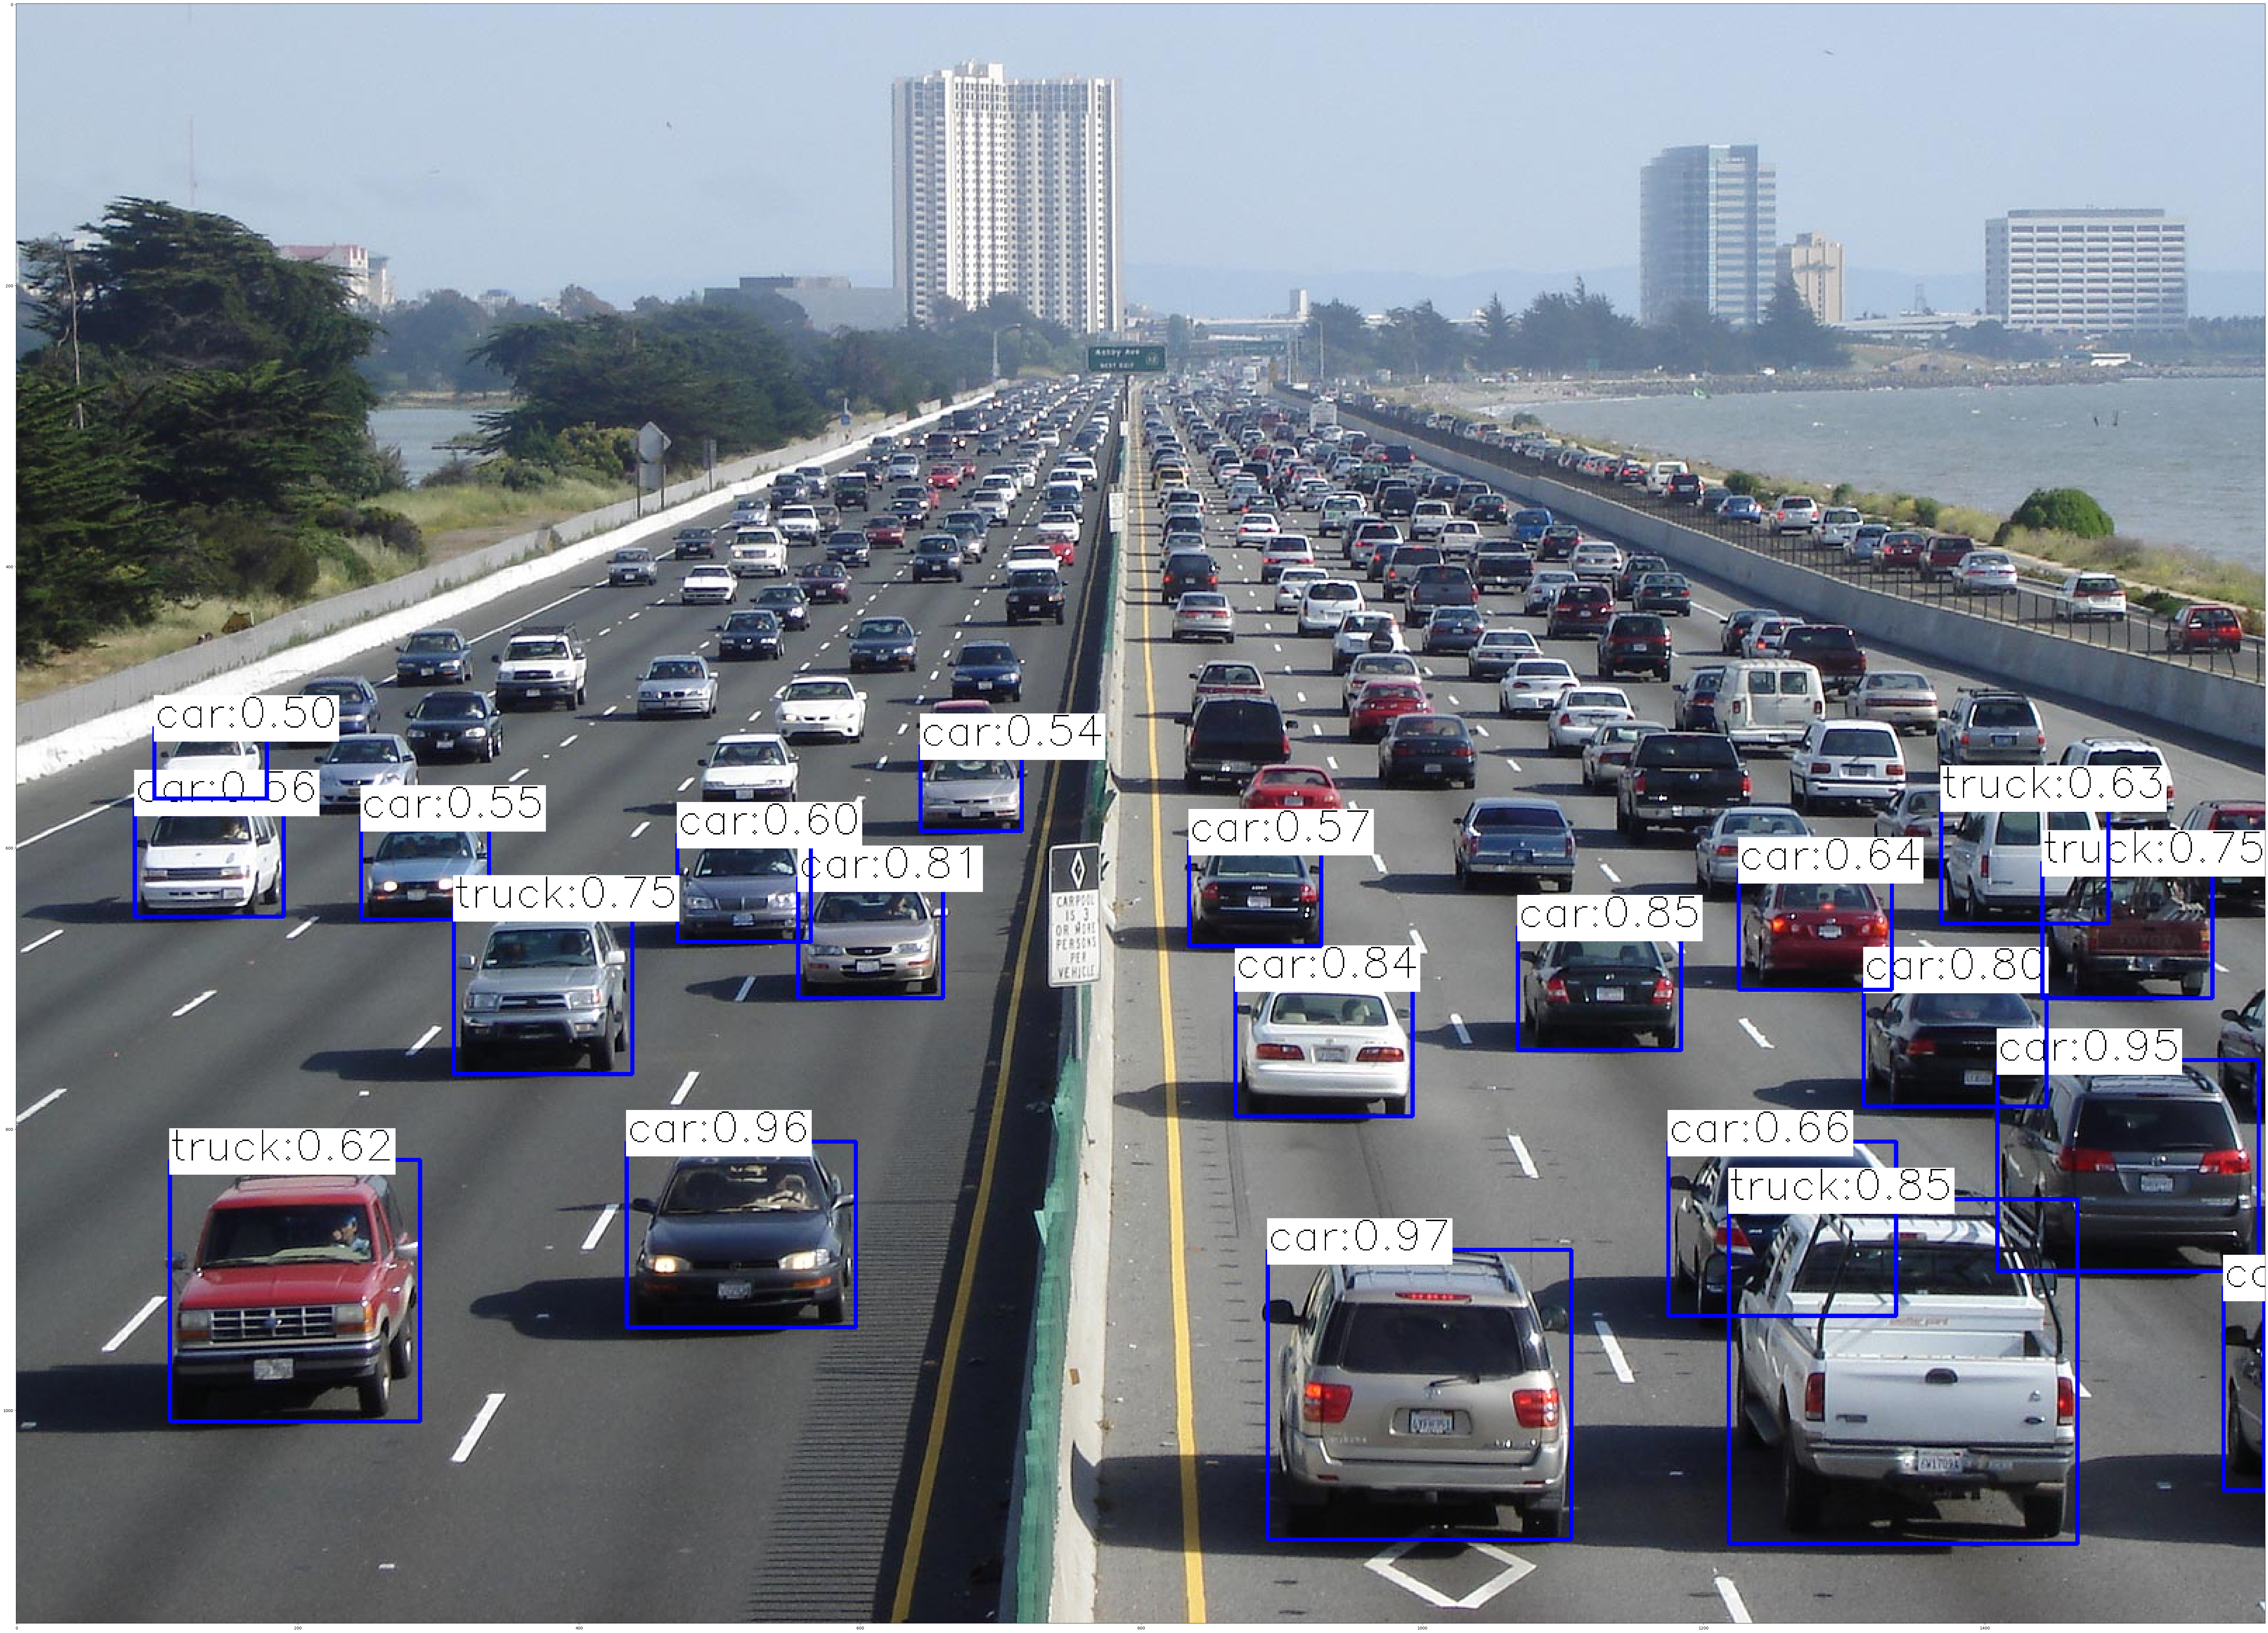

In [8]:
from tqdm import tqdm
import time
def get_fps(image, net, times):
  total_time = 0
  for _ in tqdm(range(times)):
    start = time.time()
    classes, confidences, boxes = net.detect(frame, confThreshold=0.1, nmsThreshold=0.4)
    end = time.time()
    total_time += (end-start)

  average_frame_time = total_time * 1.0 / times
  fps = 1.0 / average_frame_time
  return fps


import cv2
import matplotlib.pyplot as plt
import time

net = cv2.dnn_DetectionModel('./yolov4.cfg', './yolov4.weights')
net.setInputSize(608, 608)
net.setInputScale(1.0 / 255)
net.setInputSwapRB(True)

frame = cv2.imread('cars.jpg')

with open('coco.names', 'rt') as f:
    names = f.read().rstrip('\n').split('\n')

start = time.time()
classes, confidences, boxes = net.detect(frame, confThreshold=0.5, nmsThreshold=0.4)
end = time.time()
print("Inference time %s sec" %(end-start))
for classId, confidence, box in zip(classes.flatten(), confidences.flatten(), boxes):
  # if names[classId] != 'person':
  #   continue
  label =  '%s:%.2f' % (names[classId], confidence)
  labelSize, baseLine = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 1, 1)
  left, top, width, height = box
  top = max(top, labelSize[1])
  cv2.rectangle(frame, box, color=(255, 0, 0), thickness=2)
  cv2.rectangle(frame, (left, top - labelSize[1]), (left + labelSize[0], top + baseLine), (255, 255, 255), cv2.FILLED)
  cv2.putText(frame, label, (left, top), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 0))

plt.figure(figsize = (100,100))
plt.imshow(frame[:, :, ::-1])
plt.show()
# cv2.imshow('image',frame)
# cv2.waitKey(0)



In [ ]:
import cv2
import matplotlib.pyplot as plt
import time

net = cv2.dnn_DetectionModel('./yolov4.cfg', './yolov4.weights')
net.setInputSize(608, 608)
net.setInputScale(1.0 / 255)
net.setInputSwapRB(True)


with open('coco.names', 'rt') as f:
    names = f.read().rstrip('\n').split('\n')

font = cv2.FONT_HERSHEY_SIMPLEX
# Initialize and start realtime video capture
cam = cv2.VideoCapture(0)
cam.set(3, 640)  # set video widht
cam.set(4, 480)  # set video height
# # Define min window size to be recognized as a face
minW = 0.1 * cam.get(3)
minH = 0.1 * cam.get(4)
while True:
    ret, frame = cam.read()
    # img = cv2.flip(img, -1)  # Flip vertically

    classes, confidences, boxes = net.detect(frame, confThreshold=0.1, nmsThreshold=0.4)
    # image = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    for classId, confidence, box in zip(classes.flatten(), confidences.flatten(), boxes):
      #if names[classId] !=   'apple':#
        #continue
      label = '%s:%.2f' % (names[classId], confidence)
      labelSize, baseLine = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 1, 1)
      left, top, width, height = box
      top = max(top, labelSize[1])
      cv2.rectangle(frame, box, color=(255, 0, 0), thickness=2)
      cv2.rectangle(frame, (left, top - labelSize[1]), (left + labelSize[0], top + baseLine), (255, 255, 255),cv2.FILLED)
      cv2.putText(frame, label, (left, top), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 0))
      frame = cv2.cvtColor(frame[:, :, ::-1], cv2.COLOR_BGR2RGB)

    cv2.imshow('camera', frame)
    k = cv2.waitKey(10) & 0xff
    if k == 27:
      break
cam.release()
cv2.destroyAllWindows()
